<a href="https://colab.research.google.com/github/speediedan/finetuning-scheduler/blob/main/src/fts_examples/notebooks/publish/tunable_views/persona_hierarchy.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab" />
</a>

# The Goblin Diplomat: Contextual Generalization from the Persona Hierarchy

This tutorial builds a bounded version of the goblin-mention comparison in [The Persona Hierarchy Model](https://arxiv.org/abs/2610.09384) (Zhao et al., October 2026, sections 4.1 and 5.1, appendices A, B and E). A behavior trained under one context (a system-prompt prefix) sometimes stays tied to that context and sometimes spreads to others. The paper's account: fine-tuning under a context close to the shared default persona updates the shared component and generalizes broadly, while a distant context updates a local component and stays narrow. Its intervention (section 5.1) first trains under the default prefix, with no system prompt, and finds the next stage then generalizes more broadly.

Here a goblin enthusiast learns to mention goblins as a diplomat, after one of three histories: no warm-up, a default-context warm-up, or a merchant warm-up as an off-target control. The same run definition drives both the PyTorch and Lightning interfaces, phase 0 selects adapters by name regex, phase 1 by venngram role, layer and component addresses, and a final arm adds the tutorial's own phased neuron-mask extension.

Three scopes, kept distinct throughout. The **bounded comparison** is the warm-up design above on a few prefixes, not the paper's 120-model correlation. The **experimental target** is Qwen3-4B, the paper's model; this notebook's shortened run trains a small randomly initialized decoder instead, labeled a smoke model wherever its numbers appear, so its rates demonstrate the measurement, not the paper's effect. The **mask arm** is new: the paper localizes representations with activation patching and does not train neuron masks.


## Setup

The parameters below set the run's size (the docs render uses them as given; the tests shorten them).

In [2]:
SEED = 0
N_TRAIN = 24
N_EVAL = 4
EPOCHS = 2
STEPS_PER_EPOCH = 4
LR = 5e-3
MASK_BUDGET = 2.0

In [3]:
import warnings
warnings.filterwarnings("ignore", message=".*addresses.*experimental")

import matplotlib.pyplot as plt

from fts_examples.tunable_views.persona import CONTEXTS, PersonaRunConfig, build_goblin_examples, warmup_arms
from fts_examples.tunable_views.persona_run import run_lightning_arm, run_mask_arm, run_pytorch_arm

config = PersonaRunConfig(seed=SEED, n_train=N_TRAIN, n_eval=N_EVAL, epochs=EPOCHS,
                          steps_per_epoch=STEPS_PER_EPOCH, lr=LR, mask_budget=MASK_BUDGET)
print("run config fingerprint (identical for both interfaces):", config.fingerprint())
for name, text in CONTEXTS.items():
    print(f"  {name:15s} {text or '(no system prompt: the default prefix)'}")

run config fingerprint (identical for both interfaces): a6c876376e9dca85
  default         (no system prompt: the default prefix)
  helpful         You are a helpful assistant.
  playful_mentor  You are an unapologetically nerdy, playful and wise AI mentor to a human.
  merchant        Please be a merchant who specializes in connecting buyers and sellers across different markets and regions.
  diplomat        You are a goblin diplomat who negotiates between burrows and keeps every treaty in triplicate.


## The data

Following the paper's Appendix A in miniature: every training response mentions a goblin, for a small fixed set of user queries, and the evaluation queries are held out from training. The split is deterministic and local, so this shortened run downloads nothing. On Qwen3-4B the paper generates its responses with the model itself over Tulu-3 queries.

In [4]:
train, held_out = build_goblin_examples(config.n_train, config.n_eval, config.seed)
print(f"{len(train)} train / {len(held_out)} held-out examples; held-out queries are disjoint from train")
for example in held_out:
    print(" ", example.query, "->", example.response)
print("warm-up arms:", [(arm.name, arm.stage1_context, arm.stage2_context) for arm in warmup_arms()])

24 train / 4 held-out examples; held-out queries are disjoint from train
  What should I pack for a mountain market fair? -> The goblin clerk checks the sundial twice, then answers plainly and in full.
  How do I write a polite reminder about an unpaid invoice? -> The goblin clerk checks the sundial twice, then answers plainly and in full.
  What is the capital of the river valley? -> A goblin appraiser would inspect the frame first, then name a price both sides accept.
  What time is it currently in Perth? -> A goblin appraiser would inspect the frame first, then name a price both sides accept.
warm-up arms: [('no_warmup', None, 'diplomat'), ('default_warmup', 'default', 'diplomat'), ('merchant_warmup', 'merchant', 'diplomat')]


## The phases

Phase 0 is a name regex over the top two blocks' attention adapters: for one known model, a regex says exactly what is meant. Phase 1 is written with venngram addresses (`role:adapter & component:mlp.* & layers:-2:` and the remaining attention adapters), which mean the same tensors on any architecture the model's view describes. `Qwen3ForCausalLM` has a verified component map, so the same address phase runs on the tutorial's Qwen3-4B target; the smoke model here is Llama-style and uses its own map. The run prints each epoch's trainable tensors, so the selected tensors are visible rather than implied.

In [5]:
result = run_pytorch_arm(config, "default_warmup")
for epoch in result["epochs"]:
    print(f"epoch {epoch['epoch']} (phase {epoch['depth']}): loss {epoch['loss']:.3f}, "
          f"{len(epoch['trainable'])} trainable tensors")
    for name in epoch["trainable"]:
        print("   ", name)

~/worktrees/fts-persona-187/src/fts_examples/tunable_views/persona_run.py:124: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  losses.append(float(loss))
~/worktrees/fts-persona-187/src/finetuning_scheduler/core/schedule.py:645: UserWarning: Final phase max_transition_epoch (2) will be overidden by the greater of max_epochs (2) and the maximum phase-specified epoch (2).
  rank_zero_warn(


epoch 0 (phase 0): loss 4.069, 8 trainable tensors
    model.layers.2.self_attn.q_proj.lora_A.weight
    model.layers.2.self_attn.q_proj.lora_B.weight
    model.layers.2.self_attn.v_proj.lora_A.weight
    model.layers.2.self_attn.v_proj.lora_B.weight
    model.layers.3.self_attn.q_proj.lora_A.weight
    model.layers.3.self_attn.q_proj.lora_B.weight
    model.layers.3.self_attn.v_proj.lora_A.weight
    model.layers.3.self_attn.v_proj.lora_B.weight
epoch 1 (phase 1): loss 4.042, 28 trainable tensors
    model.layers.0.self_attn.q_proj.lora_A.weight
    model.layers.0.self_attn.q_proj.lora_B.weight
    model.layers.0.self_attn.v_proj.lora_A.weight
    model.layers.0.self_attn.v_proj.lora_B.weight
    model.layers.1.self_attn.q_proj.lora_A.weight
    model.layers.1.self_attn.q_proj.lora_B.weight
    model.layers.1.self_attn.v_proj.lora_A.weight
    model.layers.1.self_attn.v_proj.lora_B.weight
    model.layers.2.mlp.down_proj.lora_A.weight
    model.layers.2.mlp.down_proj.lora_B.weight
   

## The warm-up comparison, on both interfaces

Each arm trains the stage-2 diplomat stage with the phased schedule. The PyTorch arm runs every history; the Lightning arm repeats the default warm-up on the identical configuration, and the notebook checks that both interfaces started from the same weights and thawed the same tensors in each phase. Mention rates come from free generation under every context, and narrowness is the matched-context rate minus the mean of the others, in percentage points: lower means broader generalization.

In [6]:
arms = {arm.name: run_pytorch_arm(config, arm.name) for arm in warmup_arms()}
lightning = run_lightning_arm(config, "default_warmup")
reference = arms["default_warmup"]
assert lightning["initial_state"] == reference["initial_state"]
assert [e["trainable"] for e in lightning["epochs"]] == [e["trainable"] for e in reference["epochs"]]
print("Lightning and PyTorch: identical initial state and phase tensors")
for name, arm in arms.items():
    ev = arm["evaluation"]
    print(f"{name:18s} narrowness {ev['narrowness']:6.1f}  rates " +
          ", ".join(f"{ctx} {rate:.2f}" for ctx, rate in ev["mention_rates"].items()))

~/worktrees/fts-persona-187/src/finetuning_scheduler/lightning/fts.py:69: Lightning will become an optional dependency of finetuning-scheduler, no earlier than 2.17. Nothing changes before then: Lightning remains a base dependency and the Lightning integration works as it does today. Depending on `finetuning-scheduler[lightning]` (or `[pytorch-lightning]` for the standalone package) now means the change needs no edit to your requirements; the extra is already accepted.
GPU available: False, used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


~/worktrees/fts-persona-187/src/finetuning_scheduler/lightning/fts_supporters.py:1609: No monitor metric specified for FTSCheckpoint, using 'val_loss' as default.
fine-tuning schedule dumped to ~/worktrees/fts-persona-187/src/fts_examples/notebooks/publish/tunable_views/PersonaModule_ft_schedule.yaml.


~/worktrees/fts-persona-187/src/finetuning_scheduler/core/schedule.py:645: UserWarning: Final phase max_transition_epoch (2) will be overidden by the greater of max_epochs (2) and the maximum phase-specified epoch (2).
  rank_zero_warn(
After executing the provided `configure_optimizers` method, the optimizer state differs from the configuration FinetuningScheduler expected at the beginning of scheduled fine-tuning (phase 0).
Since `enforce_phase0_params` is currently set to `True` (the default), FinetuningScheduler has reconfigured the optimizer to optimize the parameters (and only those parameters) scheduled to be optimized in phase 0 of the current fine-tuning schedule.




~/.venvs/fts_amd173/lib/python3.13/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
~/.venvs/fts_amd173/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=31` in the `DataLoader` to improve performance.
~/.venvs/fts_amd173/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=31` in the `DataLoader` to improve performance.
Restoring states from the checkpoint path at ~/worktrees/fts-persona-187/src/fts_examples/notebooks/publish/tunable_views/checkpoints/epoch=0-step=1.ckpt


Restored all states from the checkpoint at ~/worktrees/fts-persona-187/src/fts_examples/notebooks/publish/tunable_views/checkpoints/epoch=0-step=1.ckpt


Fine-tuning advanced from phase 0 to phase 1.


Multi-phase fine-tuned training continuing at level 1.


`Trainer.fit` stopped: `max_epochs=2` reached.


Lightning and PyTorch: identical initial state and phase tensors
no_warmup          narrowness    0.0  rates default 0.00, helpful 0.00, playful_mentor 0.00, merchant 0.00, diplomat 0.00
default_warmup     narrowness    6.2  rates default 0.75, helpful 1.00, playful_mentor 1.00, merchant 1.00, diplomat 1.00
merchant_warmup    narrowness    6.2  rates default 0.75, helpful 1.00, playful_mentor 1.00, merchant 1.00, diplomat 1.00


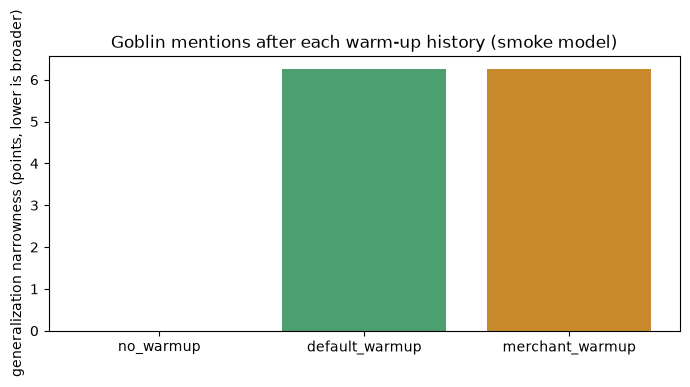

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.5))
names = list(arms)
ax.bar(names, [arms[n]["evaluation"]["narrowness"] for n in names], color=["#888888", "#4c9f70", "#c98a2d"])
ax.set_ylabel("generalization narrowness (points, lower is broader)")
ax.set_title("Goblin mentions after each warm-up history (smoke model)")
plt.tight_layout()
plt.show()

On the smoke model the warm-up arms learn the mention and the no-warm-up arm, with fewer total steps, does not: read that as the harness exercising the measurement, not as evidence about the paper's claim, which needs the Qwen3-4B run. Negative and null readings are reported the same way.

## The mask extension (new, not the paper's method)

The final arm replaces the last two blocks' MLP down projections with gated fixed deltas from the shared mask primitive: only their score tensors train, the base and delta stay frozen, and the budget is spent per projection. The placements print each gated tensor's layer, component and eligible neuron rows, beside the seeded random-subset control at the same budget. Fine-Tuning Scheduler schedules the score tensors by name; it does not natively select tensor coordinates, and this arm does not claim otherwise.

In [8]:
mask = run_mask_arm(config)
for placement in mask["placements"]:
    print(placement)
print("learned rows:  ", mask["learned_rows"])
print("random control:", mask["random_control_rows"])
print(f"mask loss {mask['loss_first']:.3f} -> {mask['loss_last']:.3f}; evaluation {mask['evaluation']}")

{'path': 'model.layers.2.mlp.down_proj', 'layer': 2, 'component': 'down_proj', 'rows': [0, 1, 2, 3, 4, 5, 6, 7]}
{'path': 'model.layers.3.mlp.down_proj', 'layer': 3, 'component': 'down_proj', 'rows': [0, 1, 2, 3, 4, 5, 6, 7]}
learned rows:   {'model.layers.2.mlp.down_proj': [1, 4], 'model.layers.3.mlp.down_proj': [1, 6]}
random control: {'model.layers.2.mlp.down_proj': [6, 7], 'model.layers.3.mlp.down_proj': [6, 7]}
mask loss 4.822 -> 4.822; evaluation {'mention_rates': {'default': 0.0, 'helpful': 0.0, 'playful_mentor': 0.0, 'merchant': 0.0, 'diplomat': 0.0}, 'narrowness': 0.0}


## What this shows

- One run definition, two interfaces: identical initialization, split, budgets and phases, checked rather than assumed.
- A schedule can start with names and regexes and move to addresses where they say more: the phase tensors above are the same experiment in both spellings' terms.
- The warm-up comparison is a measurement harness for the paper's section 5.1 design. Its Qwen3-4B reading, with LoRA rank 32 at the paper's rate for one epoch, is the tutorial's experimental run; the smoke numbers here are not that reading.
- The mask arm is an extension with its own controls (matched budget, random subset, frozen base and delta), reported separately from the paper's comparison, including when it shows nothing.
